# Decision Tree Comparison: ID3, C4.5, and CART

This notebook implements three **categorical classification** trees using only the Python standard library. It includes the dataset, root-node calculations (entropy, information gain, gain ratio, and Gini), full learned trees, split-by-split computations, training accuracy, and leave-one-out accuracy.

**Important:** The C4.5 implementation is the unpruned, categorical gain-ratio component of C4.5, including the average-information-gain safeguard. Full C4.5 additionally supports numeric thresholds, missing values, and pruning.

## Dataset

Target: **Buy** (Yes/No), 16 synthetic transactions. Duplicate rows represent repeated observations.

| ID | Channel | Discount | Returning | Buy |
|---:|---|---|---|---|
| 1 | Store | No | No | No |
| 2 | Referral | Yes | No | Yes |
| 3 | Store | Yes | No | No |
| 4 | Store | No | Yes | No |
| 5 | Online | Yes | No | Yes |
| 6 | Referral | No | Yes | No |
| 7 | Online | Yes | No | Yes |
| 8 | Referral | Yes | Yes | Yes |
| 9 | Online | Yes | No | Yes |
| 10 | Online | No | Yes | Yes |
| 11 | Referral | Yes | Yes | Yes |
| 12 | Store | No | No | No |
| 13 | Store | Yes | Yes | Yes |
| 14 | Referral | No | No | No |
| 15 | Online | Yes | Yes | Yes |
| 16 | Online | No | No | Yes |

## Split formulas

- Entropy: $H(S)=-\sum_i p_i\log_2 p_i$
- Information gain: $IG(S,A)=H(S)-\sum_v (|S_v|/|S|)H(S_v)$
- Gain ratio: $GR(A)=IG(S,A)/SplitInfo(A)$
- Gini impurity: $G(S)=1-\sum_i p_i^2$

Run the next cell to reproduce the computations and learned trees. No additional files or packages are required.


In [ ]:
"""Educational comparison: ID3, C4.5-style gain ratio, CART (categorical).
"""
from __future__ import annotations

import csv
import itertools
import math
from collections import Counter, defaultdict
from io import StringIO

DATA_CSV = 'ID,Channel,Discount,Returning,Buy\n1,Store,No,No,No\n2,Referral,Yes,No,Yes\n3,Store,Yes,No,No\n4,Store,No,Yes,No\n5,Online,Yes,No,Yes\n6,Referral,No,Yes,No\n7,Online,Yes,No,Yes\n8,Referral,Yes,Yes,Yes\n9,Online,Yes,No,Yes\n10,Online,No,Yes,Yes\n11,Referral,Yes,Yes,Yes\n12,Store,No,No,No\n13,Store,Yes,Yes,Yes\n14,Referral,No,No,No\n15,Online,Yes,Yes,Yes\n16,Online,No,No,Yes'
FEATURES = ('Channel', 'Discount', 'Returning')
TARGET = 'Buy'
EPS = 1e-12


def load_data():
    return list(csv.DictReader(StringIO(DATA_CSV)))


def entropy(labels):
    counts = Counter(labels)
    n = len(labels)
    return -sum((count / n) * math.log2(count / n)
                for count in counts.values()) if n else 0.0


def gini(labels):
    counts = Counter(labels)
    n = len(labels)
    return 1.0 - sum((count / n) ** 2 for count in counts.values()) if n else 0.0


def labels_of(rows):
    return [row[TARGET] for row in rows]


def majority(rows):
    counts = Counter(labels_of(rows))
    # Alphabetical tie break ("No" before "Yes") for repeatability.
    return sorted(counts, key=lambda cls: (-counts[cls], cls))[0]


def partitions(rows, feature):
    groups = defaultdict(list)
    for row in rows:
        groups[row[feature]].append(row)
    return dict(sorted(groups.items()))


def multiway_scores(rows, features):
    base_entropy = entropy(labels_of(rows))
    n = len(rows)
    result = {}
    for feature in features:
        groups = partitions(rows, feature)
        conditional = sum(len(v) / n * entropy(labels_of(v))
                          for v in groups.values())
        split_info = entropy([row[feature] for row in rows])
        gain = base_entropy - conditional
        result[feature] = {
            'gain': gain,
            'split_info': split_info,
            'gain_ratio': gain / split_info if split_info > EPS else 0.0,
            'conditional_entropy': conditional,
        }
    return result


def build_multiway(rows, features, method, audit, path='ROOT'):
    answer = majority(rows)
    if len(set(labels_of(rows))) == 1 or not features:
        return {'prediction': answer}

    scores = multiway_scores(rows, features)
    positive = [f for f in features if scores[f]['gain'] > EPS]
    if not positive:
        return {'prediction': answer}

    if method == 'ID3':
        selected = max(positive, key=lambda f: (scores[f]['gain'], -FEATURES.index(f)))
    else:
        # C4.5 gain-ratio criterion with Quinlan's average-gain safeguard.
        avg_gain = sum(scores[f]['gain'] for f in positive) / len(positive)
        candidates = [f for f in positive if scores[f]['gain'] + EPS >= avg_gain]
        selected = max(candidates,
                       key=lambda f: (scores[f]['gain_ratio'],
                                      scores[f]['gain'], -FEATURES.index(f)))

    audit.append({'method': method, 'path': path, 'n': len(rows),
                  'class_counts': dict(Counter(labels_of(rows))),
                  'chosen': selected, 'scores': scores})
    remaining = tuple(f for f in features if f != selected)
    branches = {}
    for value, group in partitions(rows, selected).items():
        branches[value] = build_multiway(
            group, remaining, method, audit, path + f' -> {selected}={value}')
    return {'feature': selected, 'branches': branches, 'prediction': answer}


def all_binary_splits(values):
    """Every distinct unordered binary partition of categorical values."""
    values = sorted(values)
    first = values[0]
    rest = values[1:]
    # Force the first category into left group to eliminate L/R duplicates.
    for size in range(len(values) - 1):
        for extra in itertools.combinations(rest, size):
            yield tuple(sorted((first, *extra)))


def cart_scores(rows, features):
    parent_impurity = gini(labels_of(rows))
    possible = []
    for feature in features:
        groups = partitions(rows, feature)
        if len(groups) < 2:
            continue
        for left_values in all_binary_splits(groups):
            left_set = set(left_values)
            left = [r for r in rows if r[feature] in left_set]
            right = [r for r in rows if r[feature] not in left_set]
            weighted_gini = (len(left) / len(rows) * gini(labels_of(left))
                             + len(right) / len(rows) * gini(labels_of(right)))
            possible.append({'feature': feature, 'left_values': left_values,
                             'weighted_gini': weighted_gini,
                             'improvement': parent_impurity - weighted_gini})
    return sorted(possible,
                  key=lambda s: (s['weighted_gini'],
                                 FEATURES.index(s['feature']), s['left_values']))


def build_cart(rows, audit, path='ROOT'):
    answer = majority(rows)
    if len(set(labels_of(rows))) == 1:
        return {'prediction': answer}
    candidates = cart_scores(rows, FEATURES)
    if not candidates or candidates[0]['improvement'] <= EPS:
        return {'prediction': answer}
    choice = candidates[0]
    feature, left_values = choice['feature'], choice['left_values']
    left_set = set(left_values)
    left = [r for r in rows if r[feature] in left_set]
    right = [r for r in rows if r[feature] not in left_set]
    audit.append({'method': 'CART', 'path': path, 'n': len(rows),
                  'class_counts': dict(Counter(labels_of(rows))),
                  'chosen': feature, 'left_values': left_values,
                  'weighted_gini': choice['weighted_gini'],
                  'improvement': choice['improvement'],
                  'scores': candidates})
    return {'feature': feature, 'left_values': left_values,
            'left': build_cart(left, audit, path + f' -> {feature} in {left_values}'),
            'right': build_cart(right, audit, path + f' -> {feature} not in {left_values}'),
            'prediction': answer}


def predict(tree, row):
    node = tree
    while 'feature' in node:
        feature = node['feature']
        if 'branches' in node:
            branch = node['branches'].get(row[feature])
            if branch is None:  # Previously unseen category
                return node['prediction']
            node = branch
        else:
            if row[feature] in node['left_values']:
                node = node['left']
            else:
                node = node['right']
    return node['prediction']


def make_tree(rows, method, audit=None):
    audit = [] if audit is None else audit
    if method == 'CART':
        return build_cart(rows, audit)
    return build_multiway(rows, FEATURES, method, audit)


def print_tree(node, prefix=''):
    if 'feature' not in node:
        print(f'{prefix}Predict {node["prediction"]}')
        return
    feature = node['feature']
    if 'branches' in node:
        for value, child in node['branches'].items():
            print(f'{prefix}IF {feature} = {value}:')
            print_tree(child, prefix + '  ')
    else:
        group = ', '.join(node['left_values'])
        print(f'{prefix}IF {feature} in {{{group}}}:')
        print_tree(node['left'], prefix + '  ')
        print(f'{prefix}ELSE:')
        print_tree(node['right'], prefix + '  ')


def tree_stats(tree):
    if 'feature' not in tree:
        return 0, 1  # depth, leaves
    children = (list(tree['branches'].values()) if 'branches' in tree
                else [tree['left'], tree['right']])
    child_stats = [tree_stats(c) for c in children]
    return 1 + max(d for d, _ in child_stats), sum(n for _, n in child_stats)


def accuracy(y_true, y_pred):
    return sum(a == b for a, b in zip(y_true, y_pred)) / len(y_true)


def leave_one_out_accuracy(rows, method):
    predicted = []
    for i, row in enumerate(rows):
        training = rows[:i] + rows[i + 1:]
        predicted.append(predict(make_tree(training, method), row))
    return accuracy(labels_of(rows), predicted), predicted


def main():
    rows = load_data()
    print('DATASET:', len(rows), 'records', dict(Counter(labels_of(rows))))
    print(f'Parent entropy: {entropy(labels_of(rows)):.6f}')
    print(f'Parent Gini: {gini(labels_of(rows)):.6f}\n')
    print('ROOT ATTRIBUTE COMPUTATIONS')
    scores = multiway_scores(rows, FEATURES)
    cart_options = cart_scores(rows, FEATURES)
    for f in FEATURES:
        best_cart = min((s for s in cart_options if s['feature'] == f),
                        key=lambda s: s['weighted_gini'])
        sc = scores[f]
        print(f'{f:10s}  IG={sc["gain"]:.6f}  SplitInfo={sc["split_info"]:.6f} '
              f' GainRatio={sc["gain_ratio"]:.6f} '
              f' BestBinaryGini={best_cart["weighted_gini"]:.6f} '
              f' CART-left={best_cart["left_values"]}')

    print('\nDETAILED SPLITS, TREES, AND EVALUATION')
    print('Note: LOOCV is an exploratory estimate on only 16 records.')
    for method in ('ID3', 'C4.5', 'CART'):
        audit = []
        tree = make_tree(rows, method, audit)
        preds = [predict(tree, row) for row in rows]
        train_accuracy = accuracy(labels_of(rows), preds)
        loo_accuracy, loo_predictions = leave_one_out_accuracy(rows, method)
        depth, leaves = tree_stats(tree)
        print(f'\n======== {method} ========')
        print_tree(tree)
        print(f'Train accuracy: {train_accuracy:.2%} '
              f'({round(train_accuracy*len(rows))}/{len(rows)})')
        print(f'LOOCV accuracy: {loo_accuracy:.2%} '
              f'({round(loo_accuracy*len(rows))}/{len(rows)})')
        print(f'Depth: {depth}; Leaves: {leaves}')
        print('SPLIT AUDIT:')
        for entry in audit:
            print(f' {entry["path"]} | n={entry["n"]} '
                  f'| labels={entry["class_counts"]} | choose={entry["chosen"]}')
            if method != 'CART':
                for f, sc in entry['scores'].items():
                    print(f'   {f}: IG={sc["gain"]:.6f}, '
                          f'GR={sc["gain_ratio"]:.6f}')
            else:
                grouped = defaultdict(list)
                for sc in entry['scores']:
                    grouped[sc['feature']].append(sc)
                for f, options in grouped.items():
                    best = min(options, key=lambda q: q['weighted_gini'])
                    print(f'   {f}: best-left={best["left_values"]}; '
                          f'weighted-Gini={best["weighted_gini"]:.6f}')
    print('\nInterpretation: A 100% training score is not evidence of future accuracy.')


if __name__ == '__main__':
    main()


DATASET: 16 records {'No': 6, 'Yes': 10}
Parent entropy: 0.954434
Parent Gini: 0.468750

ROOT ATTRIBUTE COMPUTATIONS
Channel     IG=0.425409  SplitInfo=1.579434  GainRatio=0.269343  BestBinaryGini=0.300000  CART-left=('Online',)
Discount    IG=0.293736  SplitInfo=0.988699  GainRatio=0.297093  BestBinaryGini=0.289683  CART-left=('No',)
Returning   IG=0.019338  SplitInfo=0.988699  GainRatio=0.019560  BestBinaryGini=0.456349  CART-left=('No',)

DETAILED SPLITS, TREES, AND EVALUATION
Note: LOOCV is an exploratory estimate on only 16 records.

======== ID3 ========
IF Channel = Online:
  Predict Yes
IF Channel = Referral:
  IF Discount = No:
    Predict No
  IF Discount = Yes:
    Predict Yes
IF Channel = Store:
  IF Discount = No:
    Predict No
  IF Discount = Yes:
    IF Returning = No:
      Predict No
    IF Returning = Yes:
      Predict Yes
Train accuracy: 100.00% (16/16)
LOOCV accuracy: 81.25% (13/16)
Depth: 3; Leaves: 6
SPLIT AUDIT:
 ROOT | n=16 | labels={'No': 6, 'Yes': 10} | choo

## Comparison and interpretation

| Model | Root attribute | Depth | Leaves | Training accuracy | Leave-one-out accuracy |
|---|---|---:|---:|---:|---:|
| ID3 | Channel | 3 | 6 | 100% | 81.25% (13/16) |
| C4.5-style | Discount | 3 | 7 | 100% | 87.50% (14/16) |
| CART | Discount | 3 | 5 | 100% | 81.25% (13/16) |

Because the dataset has only 16 synthetic records, these results illustrate the algorithms rather than establishing general model superiority. CART happens to form the fewest leaves on this dataset; C4.5 has a one-observation advantage on leave-one-out predictions.


In [ ]:

import pandas as pd

rows = load_data()
y_true = labels_of(rows)

results = []

for model in ["ID3", "C4.5", "CART"]:
    score, y_pred = leave_one_out_accuracy(rows, model)

    TP = sum(a == "Yes" and p == "Yes" for a, p in zip(y_true, y_pred))
    TN = sum(a == "No" and p == "No" for a, p in zip(y_true, y_pred))
    FP = sum(a == "No" and p == "Yes" for a, p in zip(y_true, y_pred))
    FN = sum(a == "Yes" and p == "No" for a, p in zip(y_true, y_pred))

    acc_score = (TP + TN) / len(y_true)
    prec_score = TP / (TP + FP) if (TP + FP) else 0
    rec_score = TP / (TP + FN) if (TP + FN) else 0
    spec_score = TN / (TN + FP) if (TN + FP) else 0

    f1_score_value = (
        2 * prec_score * rec_score / (prec_score + rec_score)
        if (prec_score + rec_score) else 0
    )

    results.append({
        "Algorithm": model,
        "Accuracy": acc_score,
        "Precision": prec_score,
        "Recall": rec_score,
        "Specificity": spec_score,
        "F1 Score": f1_score_value
    })

df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))


Algorithm  Accuracy  Precision  Recall  Specificity  F1 Score
      ID3    0.8125   0.818182     0.9     0.666667  0.857143
     C4.5    0.8750   0.900000     0.9     0.833333  0.900000
     CART    0.8125   0.888889     0.8     0.833333  0.842105


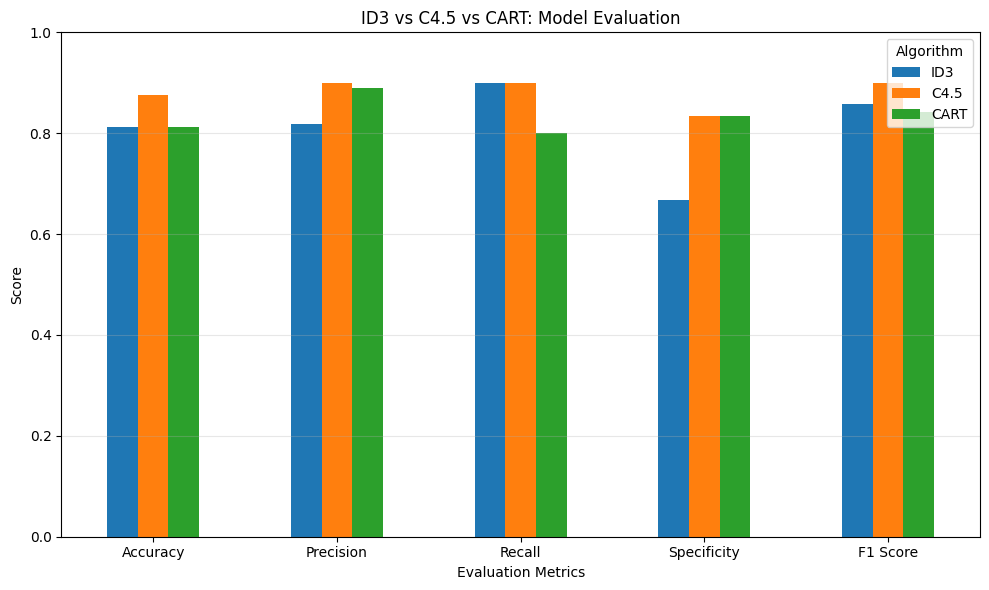

In [ ]:

import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall",
           "Specificity", "F1 Score"]

df_results.set_index("Algorithm")[metrics].T.plot(
    kind="bar", figsize=(10, 6)
)

plt.title("ID3 vs C4.5 vs CART: Model Evaluation")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Algorithm")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
